# 问题3：条件生成、风味指纹与受约束迁移

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
OUT=ROOT/'outputs/competition_completion_v1'
pd.set_option('display.max_rows',160)
pd.set_option('display.max_columns',25)

## 说明

按训练集风格条件进行近邻谱插值，参数规则固定，不基于测试成绩选取。输出是附件1混合尺度上的统计化合物谱，不是已验证浓度配方或酿造工艺。插值不自动保证汇总指标恒等式。四个缺陷原生字段完全冻结；未知值保持未知；Stale hops仅有模型代理约束，非实测缺陷保证。

In [2]:
v=pd.read_csv(OUT/'q3_generation_heldout_validation.csv'); display(v.groupby('mode').mean(numeric_only=True)); display(v); display(pd.read_csv(OUT/'q3_style_diagnostic.csv')); display(pd.read_csv(OUT/'q3_style_sensory_profiles.csv').query("style in ['Tripel','Kriek','Lambic']"))

,n_train,n_test,marginal_wasserstein,mean_shift_RMS,real_nearest_train,generated_nearest_train,duplicate_fraction,outside_training_range,generated_missing_rate
mode,,,,,,,,,
conditional_local,9.090909,2.272727,0.747896,2.364091,2.457155,0.210414,0.0,0.0,0.001844
conditional_resample,9.090909,2.272727,0.759844,2.361950,2.457155,0.000000,1.0,0.0,0.001072
unconditional_local,9.090909,2.272727,0.829752,2.379798,2.457155,0.180643,0.0,0.0,0.002096


,style,mode,n_train,n_test,marginal_wasserstein,mean_shift_RMS,real_nearest_train,generated_nearest_train,duplicate_fraction,outside_training_range,generated_missing_rate
0,Amber,conditional_local,10,2,0.801909,1.132679,1.362666,0.177542,0.0,0.0,0.000779
1,Amber,conditional_resample,10,2,0.813076,1.144398,1.362666,0.000000,1.0,0.0,0.000173
2,Amber,unconditional_local,10,2,0.836219,1.090957,1.362666,0.190396,0.0,0.0,0.002424
3,Blond,conditional_local,25,6,0.407673,0.460315,0.894489,0.197617,0.0,0.0,0.002165
4,Blond,conditional_resample,25,6,0.412740,0.469711,0.894489,0.000000,1.0,0.0,0.001558
5,Blond,unconditional_local,25,6,0.416147,0.474515,0.894489,0.194343,0.0,0.0,0.001861
6,Brett/cofermented,conditional_local,5,1,0.815384,0.978186,0.781249,0.251783,0.0,0.0,0.000000
7,Brett/cofermented,conditional_resample,5,1,0.764009,0.861587,0.781249,0.000000,1.0,0.0,0.000000
8,Brett/cofermented,unconditional_local,5,1,0.702412,0.711680,0.781249,0.173222,0.0,0.0,0.002121
9,Brown,conditional_local,10,2,0.553102,0.683906,0.835087,0.165872,0.0,0.0,0.000693


,heldout_style_accuracy,heldout_balanced_accuracy,generated_condition_agreement
0,0.6,0.55303,0.989545


,style,target,predicted_mean,predicted_q05,predicted_q95,observed_training_mean
550,Kriek,A_malt_all,-0.465037,-0.930286,-0.106708,-0.502183
551,Kriek,A_malt_grain,-0.194920,-0.357739,0.055058,-0.263301
552,Kriek,A_malt_bread,-0.121538,-0.338995,0.126201,-0.206825
553,Kriek,A_malt_cara,-0.352140,-0.704348,-0.068603,-0.383038
554,Kriek,A_malt_burn,-0.205978,-0.259842,-0.102439,-0.204462
555,Kriek,A_hops_all,-0.589449,-0.857373,-0.233051,-0.860889
556,Kriek,A_hops_citrus,-0.292375,-0.343997,-0.219235,-0.437701
557,Kriek,A_hops_tropical,-0.233367,-0.300489,-0.146938,-0.337200
558,Kriek,A_hops_noble,-0.403753,-0.683480,0.023846,-0.616711
559,Kriek,A_hops_woody,-0.071432,-0.184052,0.008037,-0.131238


,source_beer,source_split,target_style,target_donor_beer,alpha,source_target_distance,transferred_target_distance,distance_improvement,relative_distance_improvement,movement,source_stale_predicted,transferred_stale_predicted,source_stale_auxiliary_guard,transferred_stale_auxiliary_guard,defect_native_exactly_preserved,source_trip_probability,transferred_trip_probability,status
0,28,heldout_test,Tripel,199,0.75,0.840242,0.212406,0.627836,0.747209,0.629709,-0.055073,-0.055073,0.190278,0.037354,True,0.071872,0.165036,feasible_improvement
1,81,training,Tripel,147,0.75,0.992219,0.268501,0.723718,0.729393,0.789474,-0.055073,-0.055073,0.545536,0.132281,True,0.037225,0.122719,feasible_improvement
2,90,training,Tripel,217,0.75,0.918034,0.273204,0.644830,0.702403,0.678910,-0.055073,-0.055073,-0.083476,-0.092353,True,0.025948,0.129976,feasible_improvement
3,96,training,Tripel,15,0.75,1.122721,0.294962,0.827759,0.737280,0.839642,-0.055073,-0.055073,0.110083,-0.178806,True,0.022889,0.103399,feasible_improvement
4,119,heldout_test,Tripel,85,0.75,0.870876,0.271271,0.599606,0.688508,0.641017,-0.055073,-0.055073,0.033920,-0.177765,True,0.041519,0.118087,feasible_improvement
5,124,training,Tripel,239,0.75,1.064395,0.278764,0.785631,0.738101,0.819147,-0.055073,-0.055073,-0.077900,-0.193487,True,0.011311,0.107443,feasible_improvement
6,139,training,Tripel,217,0.75,0.988910,0.257524,0.731386,0.739588,0.739607,-0.055073,-0.055073,-0.091661,-0.145425,True,0.024680,0.120215,feasible_improvement
7,185,training,Tripel,239,0.75,1.112001,0.301539,0.810462,0.728832,0.829125,-0.055073,-0.055073,-0.020900,-0.204171,True,0.025093,0.117253,feasible_improvement
8,209,training,Tripel,239,0.75,1.038366,0.265508,0.772858,0.744302,0.777626,-0.055073,-0.055073,-0.094103,-0.198420,True,0.020040,0.119769,feasible_improvement
9,218,training,Tripel,217,0.75,0.862671,0.221206,0.641465,0.743580,0.645932,-0.055073,-0.055073,0.208333,-0.068441,True,0.022718,0.135594,feasible_improvement


,source_beer,field,before_native,after_native,known,guarantee
0,28,DMS,1.437078,1.437078,True,native value unchanged; concentration non-wors...
1,28,X2.3.butanedione,NaN,NaN,False,"unknown retained, no safety claim"
2,28,X4VG,-2.013157,-2.013157,True,native value unchanged; concentration non-wors...
3,28,X.E..2.nonenal,0.011530,0.011530,True,native value unchanged; concentration non-wors...
4,81,DMS,0.947369,0.947369,True,native value unchanged; concentration non-wors...
5,81,X2.3.butanedione,0.284814,0.284814,True,native value unchanged; concentration non-wors...
6,81,X4VG,-2.013157,-2.013157,True,native value unchanged; concentration non-wors...
7,81,X.E..2.nonenal,0.003422,0.003422,True,native value unchanged; concentration non-wors...
8,90,DMS,0.899444,0.899444,True,native value unchanged; concentration non-wors...
9,90,X2.3.butanedione,0.236137,0.236137,True,native value unchanged; concentration non-wors...


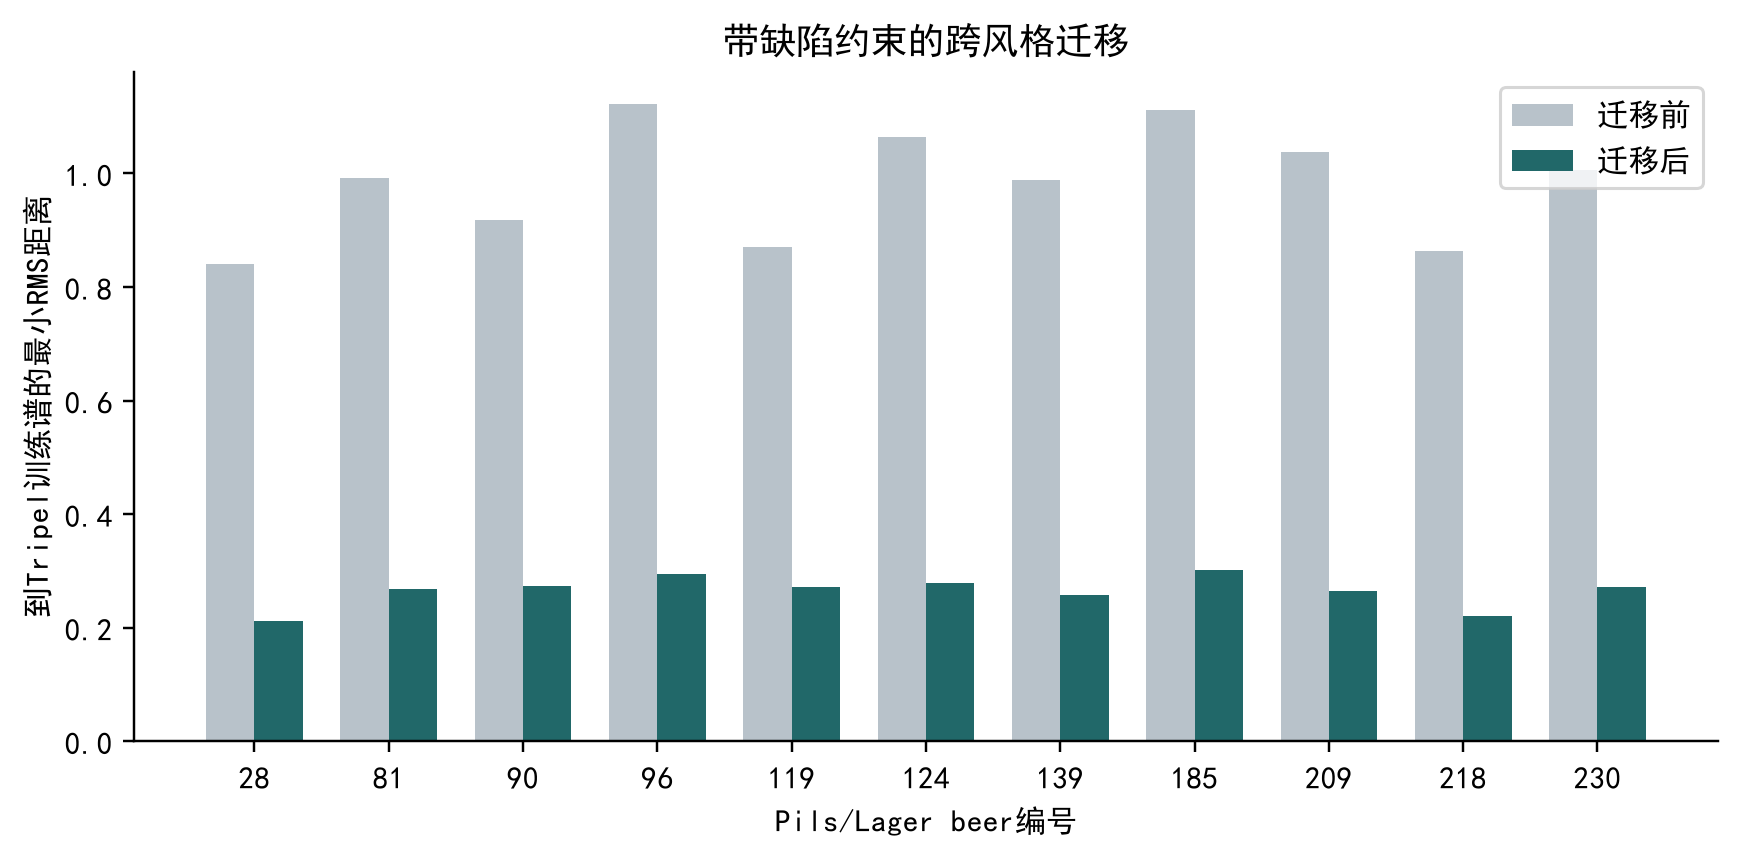

In [3]:
t=pd.read_csv(OUT/'q3_transfer_summary.csv'); display(t); assert t.defect_native_exactly_preserved.all(); assert (t.transferred_stale_auxiliary_guard<=t.source_stale_auxiliary_guard+1e-12).all(); display(pd.read_csv(OUT/'q3_transfer_defect_constraints.csv')); display(Image(filename=str(OUT/'figures/06_transfer.png')))

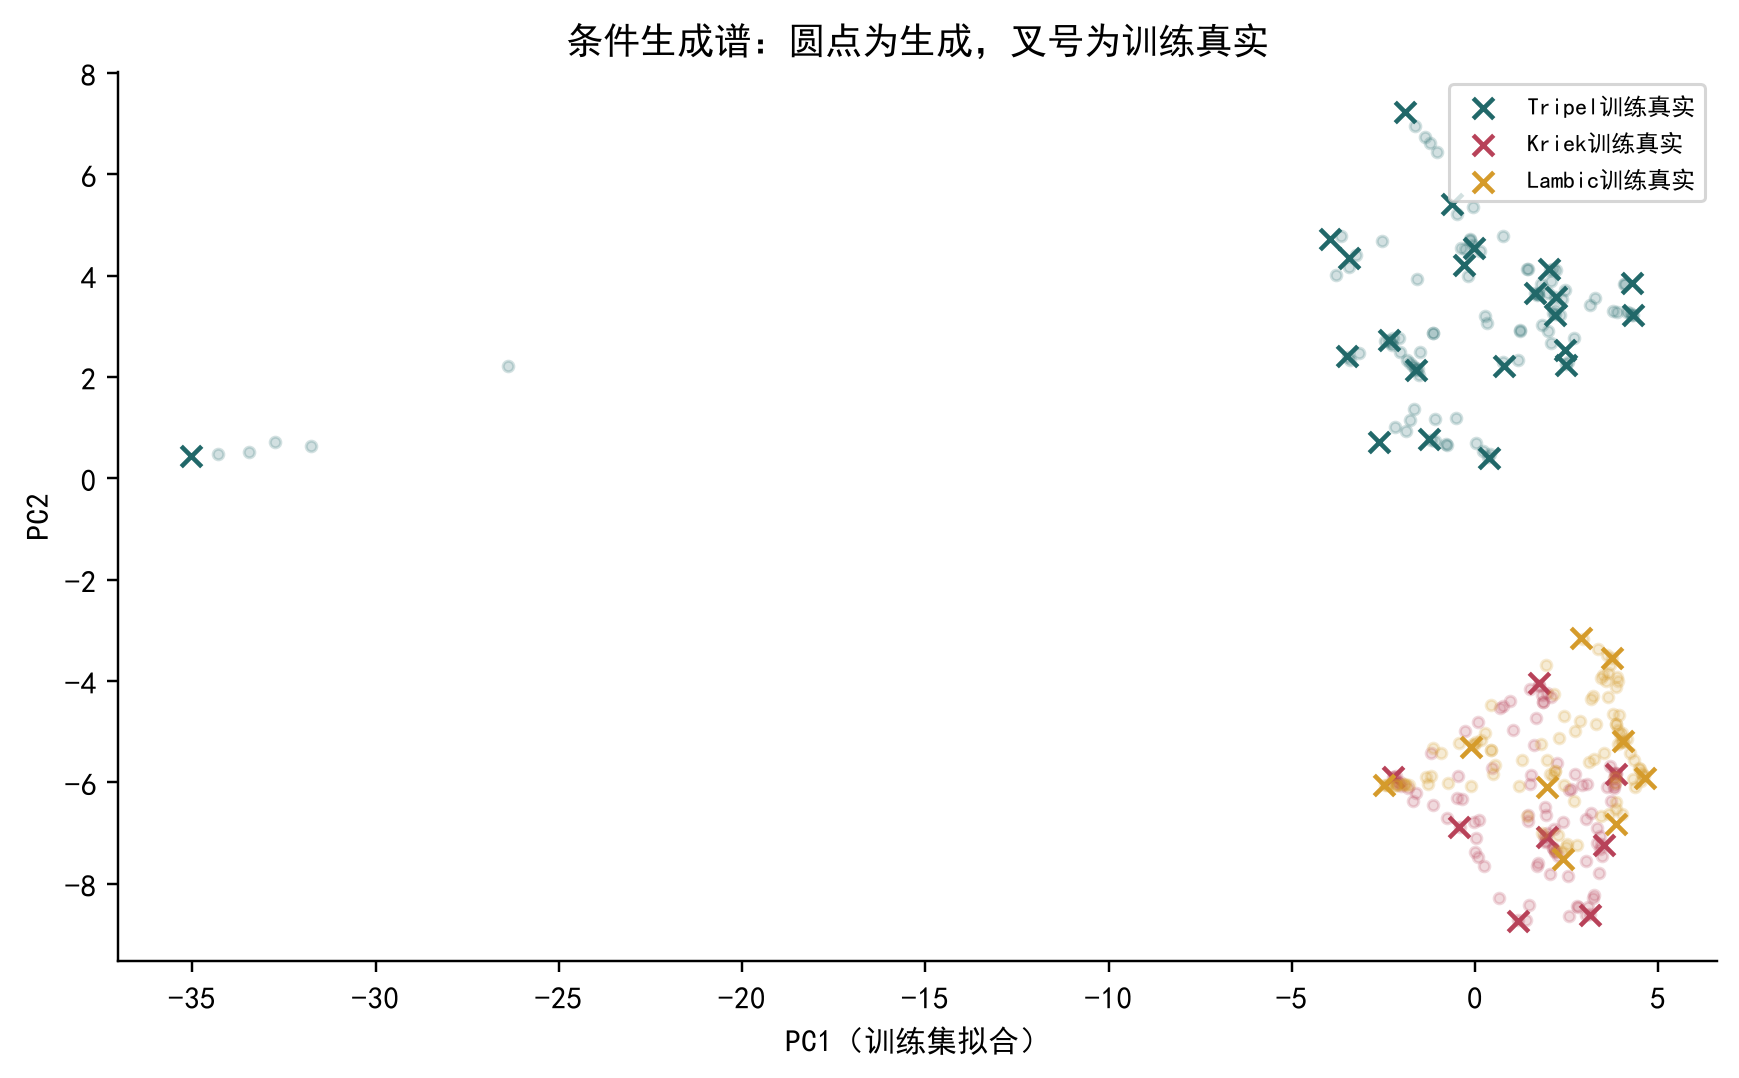

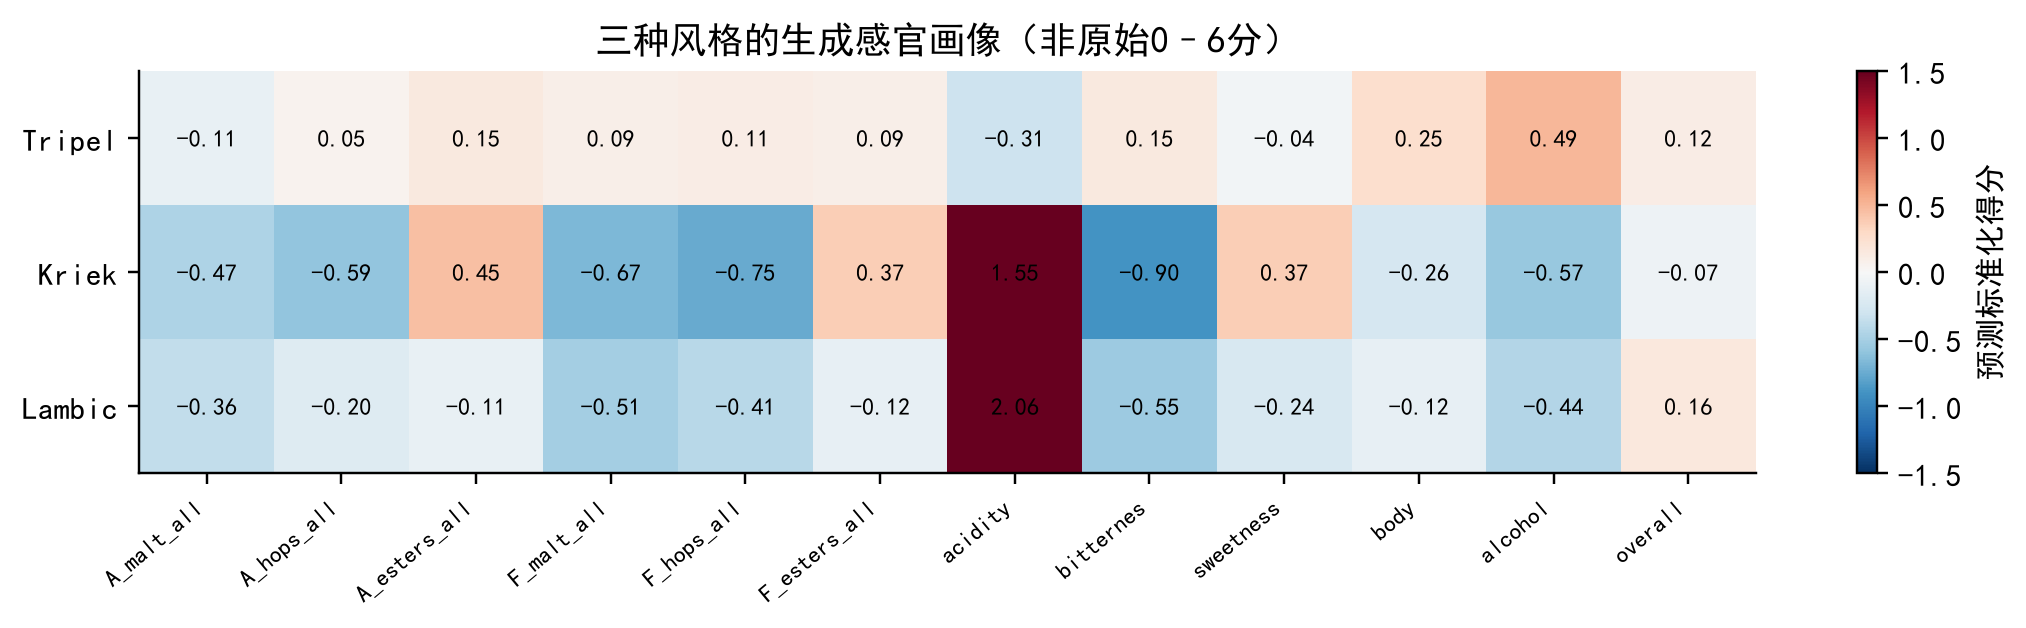

In [4]:
display(Image(filename=str(OUT/'figures/04_conditional_generation.png'))); display(Image(filename=str(OUT/'figures/05_style_profiles.png')))

## 复现

项目根目录执行：python scripts/competition_pipeline.py --stage all。随后执行 python scripts/build_competition_deliverables.py。模型载入前将 scripts 加入sys.path；只读取自己生成的joblib文件。